# 6.1 Pengembangan Graph

Graph digunakan untuk memetakan karakteristik pembelajaran mahasiswa dengan karakteristik mahasiswa lainnya. Untuk itu, diperlukan tahapan sebagai berikut:
- Input data
- Memetakan graph mahasiswa-materi
- Membuat matriks dan menghitung similarity mahasiswa
- Memetakan graph kemiripan mahasiswa


### 6.1.1 Mengambil data input dari HDFS

Data input yang diperlukan untuk graph adalah activityLog.json (untuk melihat secara detail aktivitas mahasiswa), vle (mendapatkan konteks materi) dan features_clean hasil ETL.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import StructType, StructField, StringType, IntegerType

try:
    display
except NameError:            # di luar Jupyter
    display = print

#Parameter (samakan dengan file ETL dan bab 5)
HDFS      = "hdfs://namenode:9000/data/oulad"
SUFFIX    = ""                       
GRAPH_DIR = f"{HDFS}/graph"
SEED      = 42

spark = (SparkSession.builder
         .appName("oulad-graph")
         .master("local[*]")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.shuffle.partitions", "16")
         .config("spark.hadoop.dfs.replication", "1")      
         .getOrCreate())

schema_vle_log = StructType([
    StructField("code_module", StringType()),
    StructField("code_presentation", StringType()),
    StructField("id_student", IntegerType()),
    StructField("id_site", IntegerType()),
    StructField("date", IntegerType()),
    StructField("sum_click", IntegerType()),
])

log = spark.read.schema(schema_vle_log).json(f"{HDFS}/raw/json/activityLog")

vle = (spark.read.option("header", True).option("inferSchema", True)
       .option("nullValue", "?").csv(f"{HDFS}/raw/csv/vle.csv"))

students = (spark.read.option("header", True).option("inferSchema", True)
            .csv(f"{HDFS}/processed/features_clean{SUFFIX}")
            .select("code_module", "code_presentation", "id_student", "final_result",
                    "distinct_sites", "total_click"))

print(f"log: {log.count():,} baris | vle: {vle.count():,} materi | siswa: {students.count():,}")

log: 10,655,280 baris | vle: 6,364 materi | siswa: 32,593


### 6.1.2 Graph siswa-materi

Graph ini tidak dianalisis secara langsung, hanya digunakan sebagai input untuk graph kemiripan mahasiswa.

In [2]:
stu_id = lambda: F.concat_ws("_", F.lit("s"), F.col("code_module"), F.col("code_presentation"),
                             F.col("id_student").cast("string"))
mat_id = lambda: F.concat_ws("_", F.lit("m"), F.col("code_module"), F.col("code_presentation"),
                             F.col("id_site").cast("string"))
NULL_INT, NULL_STR = F.lit(None).cast("int"), F.lit(None).cast("string")

#Vertices: siswa dan materi, dengan kolom yang sama
v_students = students.select(stu_id().alias("id"), F.lit("student").alias("type"),
                             "code_module", "code_presentation", "id_student", "final_result",
                             NULL_INT.alias("id_site"), NULL_STR.alias("activity_type"))
v_materials = vle.select(mat_id().alias("id"), F.lit("material").alias("type"),
                         "code_module", "code_presentation", NULL_INT.alias("id_student"),
                         NULL_STR.alias("final_result"), "id_site", "activity_type")
vertices = v_students.unionByName(v_materials)

assert v_students.select("id").distinct().count() == v_students.count(), "Id node siswa tidak unik"
assert v_materials.select("id").distinct().count() == v_materials.count(), "Id node materi tidak unik"

#Edges: agregasi log per pasangan siswa-materi
t0 = time.time()
edges_raw = (log.groupBy("code_module", "code_presentation", "id_student", "id_site")
                .agg(F.sum("sum_click").alias("weight"))
                .select(stu_id().alias("src"), mat_id().alias("dst"),
                        "weight", "code_module", "code_presentation")
                .cache())
n_before = edges_raw.count()

#Buang edge yang ujungnya tidak ada di tabel node
edges = (edges_raw.join(v_students.select(F.col("id").alias("src")), "src", "left_semi")
                  .join(v_materials.select(F.col("id").alias("dst")), "dst", "left_semi")
                  .cache())
n_edges = edges.count()
edges_raw.unpersist()

print(f"edge terbentuk: {n_edges:,} (dari {log.count():,} baris log) dalam {time.time() - t0:.0f} s")
print(f"edge dibuang karena node tidak ditemukan: {n_before - n_edges}")

edge terbentuk: 1,960,496 (dari 10,655,280 baris log) dalam 30 s
edge dibuang karena node tidak ditemukan: 0


### 6.1.3 Membuat matriks dan menghitung similarity mahasiswa

Dari proses 6.1.2, didapatkan sebuah graph yang memetakan hubungan antara mahasiswa dan materi. Edge yang terbentuk berkisar di angka 1,9 juta dari 10 juta baris log. Graph tersebut menyediakan informasi mengenai pola pembelajaran mahasiswa untuk graph similarity mahasiswa.

In [3]:
from scipy.sparse import csr_matrix
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

In [4]:
from pyspark.sql import Window
from pyspark.sql import functions as F

N_PER_CLASS = 25

student_sample = (
    v_students
    .select("id", "final_result")
    .filter(F.col("final_result").isNotNull())
    .withColumn(
        "rn",
        F.row_number().over(
            Window.partitionBy("final_result")
                  .orderBy(F.rand(seed=42))
        )
    )
    .filter(F.col("rn") <= N_PER_CLASS)
    .drop("rn")
)

#Periksa distribusi sampel
student_sample.groupBy("final_result").count().show()

#Ambil edge dari mahasiswa terpilih dari graph mahasiswa-materi
e_subset = (
    edges
    .join(
        student_sample.select(F.col("id").alias("src")),
        "src",
        "left_semi"
    )
    .select("src", "dst", "weight")
)

edges_pd = e_subset.toPandas()

+------------+-----+
|final_result|count|
+------------+-----+
| Distinction|   25|
|        Fail|   25|
|        Pass|   25|
|   Withdrawn|   25|
+------------+-----+



In [5]:
student_ids = edges_pd["src"].unique()
material_ids = edges_pd["dst"].unique()

student_idx = {v: i for i, v in enumerate(student_ids)}
material_idx = {v: i for i, v in enumerate(material_ids)}

#Log transform agar interaksi ekstrem tidak terlalu dominan
values = np.log1p(edges_pd["weight"].to_numpy())

X = csr_matrix(
    (
        values,
        (
            edges_pd["src"].map(student_idx),
            edges_pd["dst"].map(material_idx)
        )
    ),
    shape=(len(student_ids), len(material_ids))
)

#Normalisasi setiap mahasiswa
X = normalize(X, norm="l2")

In [6]:
#Similarity berdasarkan pola materi
pattern_similarity = cosine_similarity(X)

total_clicks = np.array([
    edges_pd.loc[
        edges_pd["src"] == sid,
        "weight"
    ].sum()
    for sid in student_ids
])

log_clicks = np.log1p(total_clicks)

#Similarity berdasarakan jumlah klik
volume_similarity = np.exp(
    -np.abs(
        log_clicks[:, None] - log_clicks[None, :]
    )
)

alpha = 0.7

#Similarity total (0.7 dari pattern dan 0.3 dari volume)
similarity = (
    alpha * pattern_similarity
    + (1 - alpha) * volume_similarity
)

### 6.1.4 Memetakan graph kemiripan mahasiswa

Setelah kemiripan mahasiswa telah dihitung, proses penyusunan graph dimulai. Pada graph ini, vertex hanya didapat dari mahasiswa dan edge adalah similarity antar mahasiswa. Ukuran node adalah jumlah klik yang dilakukan mahasiswa di VLE.

In [7]:
G = nx.Graph()

#Tambahkan node mahasiswa
for sid in student_ids:
    G.add_node(sid)

#Hubungkan 3 mahasiswa paling mirip
k = 3

for i, sid in enumerate(student_ids):
    nearest = np.argsort(similarity[i])[::-1][1:k+1]

    for j in nearest:
        other = student_ids[j]
        score = similarity[i, j]

        if score >= 0.20:
            G.add_edge(
                sid,
                other,
                weight=float(score)
            )

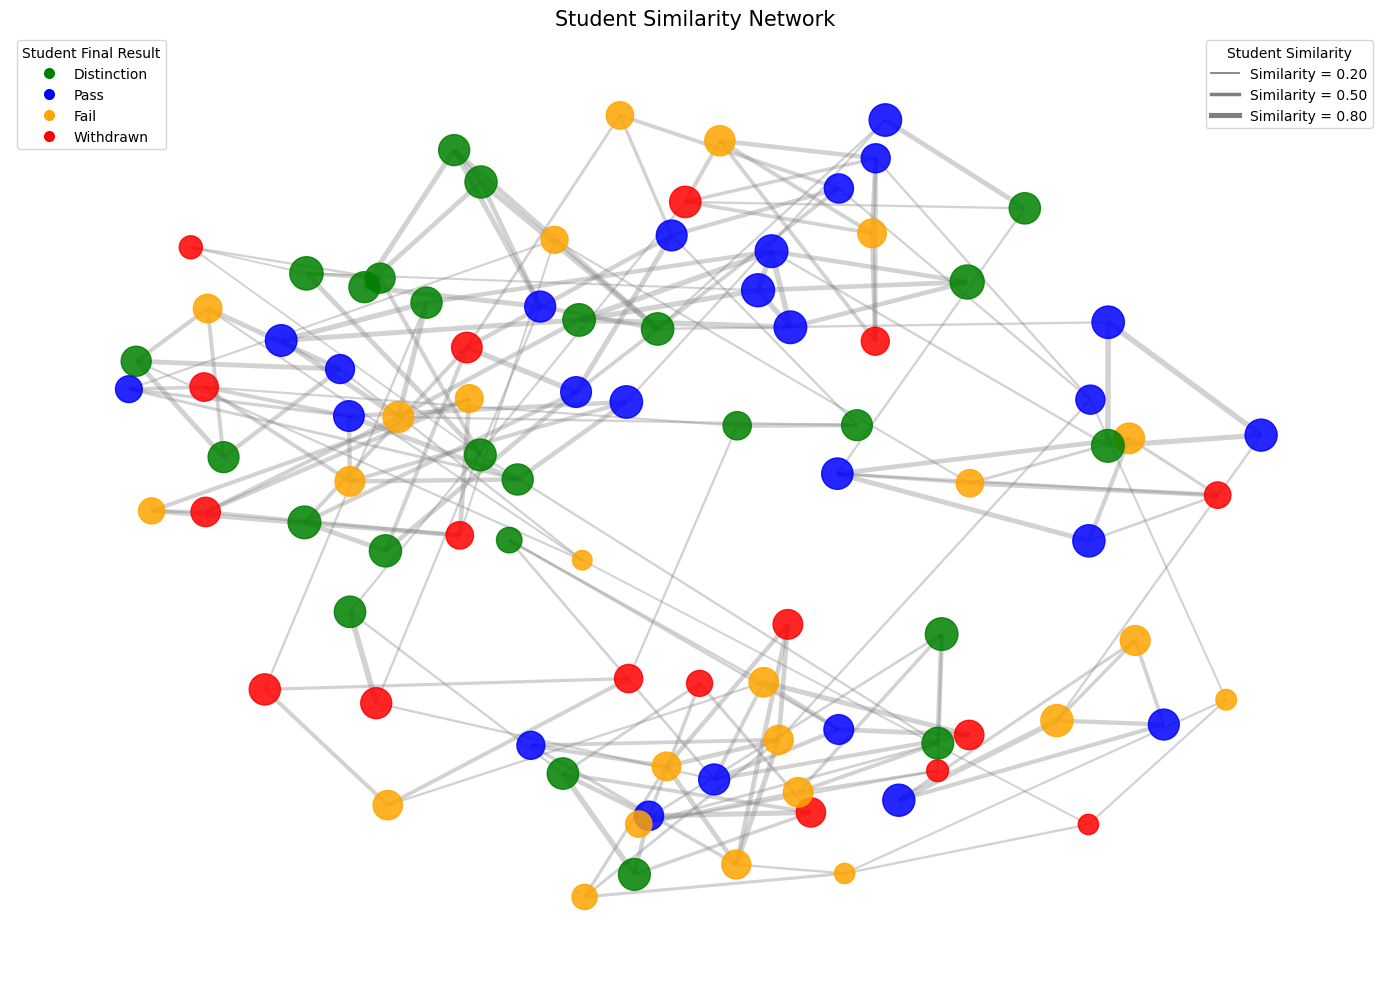

In [8]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

from matplotlib.lines import Line2D

G = nx.Graph()

#Informasi mahasiswa
student_info = (
    student_sample.toPandas()
    .set_index("id")
)

#Tambahkan node mahasiswa
for sid in student_ids:
    total_clicks = edges_pd.loc[
        edges_pd["src"] == sid, "weight"
    ].sum()

    G.add_node(
        sid,
        result=student_info.loc[sid, "final_result"],
        total_clicks=float(total_clicks)
    )

#Buat koneksi berdasarkan similarity
k = 3
threshold = 0.20

for i, sid in enumerate(student_ids):
    scores = similarity[i].copy()
    scores[i] = -1

    nearest = np.argsort(scores)[::-1][:k]

    for j in nearest:
        other = student_ids[j]
        score = similarity[i, j]

        if score >= threshold:
            G.add_edge(
                sid,
                other,
                weight=float(score)
            )

#Warna berdasarkan final_result
result_colors = {
    "Distinction": "green",
    "Pass": "blue",
    "Fail": "orange",
    "Withdrawn": "red"
}

#Force-directed layout
pos = nx.spring_layout(
    G,
    weight="weight",
    seed=42,
    k=0.5
)

#Ukuran node berdasarkan total klik
clicks = np.array([
    G.nodes[n]["total_clicks"]
    for n in G.nodes
])

node_sizes = 100 + 500 * (
    np.log1p(clicks) / max(np.log1p(clicks))
)

#Warna node
node_colors = [
    result_colors.get(G.nodes[n]["result"], "gray")
    for n in G.nodes
]

#Ketebalan edge berdasarkan similarity
edge_widths = [
    0.5 + 4 * G[u][v]["weight"]
    for u, v in G.edges
]

#Plot
fig, ax = plt.subplots(figsize=(14, 10))

nx.draw_networkx_edges(
    G, pos,
    width=edge_widths,
    alpha=0.35,
    edge_color="gray",
    ax=ax
)

nx.draw_networkx_nodes(
    G, pos,
    node_color=node_colors,
    node_size=node_sizes,
    alpha=0.85,
    ax=ax
)

#Legend kategori mahasiswa
class_legend = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        markerfacecolor=color,
        markersize=9,
        label=label
    )
    for label, color in result_colors.items()
]

legend1 = ax.legend(
    handles=class_legend,
    title="Student Final Result",
    loc="upper left"
)

ax.add_artist(legend1)

#Legend kekuatan similarity
similarity_legend = [
    Line2D(
        [0], [0],
        color="gray",
        linewidth=0.5 + 4 * score,
        label=f"Similarity = {score:.2f}"
    )
    for score in [0.2, 0.5, 0.8]
]

ax.legend(
    handles=similarity_legend,
    title="Student Similarity",
    loc="upper right"
)

ax.set_title(
    "Student Similarity Network",
    fontsize=15
)

ax.axis("off")
plt.tight_layout()
plt.show()

In [9]:
import os
import networkx as nx
import pandas as pd

OUT = "dashboard_data"
os.makedirs(OUT, exist_ok=True)

# Komunitas (Louvain): kelompok mahasiswa dengan pola belajar yang mirip
communities = nx.community.louvain_communities(G, weight="weight", seed=42)
communities = sorted(communities, key=len, reverse=True)
comm_of = {n: i + 1 for i, c in enumerate(communities) for n in c}

pagerank = nx.pagerank(G, weight="weight")
degree = dict(G.degree())

nodes_out = pd.DataFrame([{
    "id": n,
    "final_result": G.nodes[n]["result"],
    "total_clicks": G.nodes[n]["total_clicks"],
    "degree": degree[n],
    "pagerank": pagerank[n],
    "community": comm_of[n],
    "x": float(pos[n][0]),
    "y": float(pos[n][1]),
} for n in G.nodes])

edges_out = pd.DataFrame([{"source": u, "target": v, "weight": d["weight"]}
                          for u, v, d in G.edges(data=True)])

nodes_out.to_csv(f"{OUT}/graph_nodes.csv", index=False)
edges_out.to_csv(f"{OUT}/graph_edges.csv", index=False)

print(f"Bagian B selesai: {len(nodes_out)} node, {len(edges_out)} edge, "
      f"{len(communities)} komunitas")

Bagian B selesai: 91 node, 173 edge, 14 komunitas
